# Module 02 — Calculus Refresher & Gradient Descent

Almost every ML model is trained the same way: define a **loss** (how wrong the model is), then nudge the
parameters downhill until the loss is small. "Downhill" is a calculus idea, and the nudging algorithm is
**gradient descent**.

**Learning goals**
- Derivative = slope = "if I increase x a bit, how much does f change?"
- Compute derivatives numerically (finite differences) to check your math.
- Partial derivatives and the **gradient** for functions of several variables.
- The **chain rule**, the idea behind backpropagation.
- Implement gradient descent in 1-D and 2-D and see how the **learning rate** affects it.
- Use gradient descent to fit a line by minimizing mean squared error. This is your first trained model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 1. The derivative is a slope

For $f(x) = x^2$, the derivative is $f'(x) = 2x$. At $x=3$ the slope is 6: moving $x$ right by a tiny amount
$h$ increases $f$ by about $6h$.

Definition (you never need to do the limit yourself):
$$ f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h} $$

On a computer we simply pick a tiny `h`. This **numerical derivative** is slow, but it is a great tool for
checking a formula you derived by hand.

In [2]:
def f(x):
    return x ** 2

def numerical_derivative(f, x, h=1e-5):
    # central difference: average the slope just left and just right of x, which is more accurate
    return (f(x + h) - f(x - h)) / (2 * h)

for x0 in [-2.0, 0.0, 3.0]:
    print(f"x={x0:+.1f}  numerical={numerical_derivative(f, x0):+.4f}  exact 2x={2*x0:+.4f}")

x=-2.0  numerical=-4.0000  exact 2x=-4.0000
x=+0.0  numerical=+0.0000  exact 2x=+0.0000
x=+3.0  numerical=+6.0000  exact 2x=+6.0000


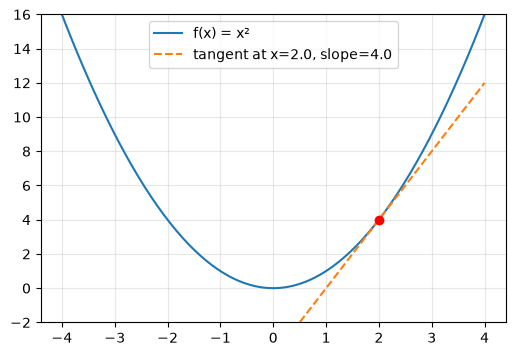

In [3]:
# Visualize: the tangent line at x0 has slope f'(x0)
xs = np.linspace(-4, 4, 200)
x0 = 2.0
slope = 2 * x0
tangent = f(x0) + slope * (xs - x0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(xs, f(xs), label="f(x) = x²")
ax.plot(xs, tangent, "--", label=f"tangent at x={x0}, slope={slope}")
ax.scatter([x0], [f(x0)], color="red", zorder=3)
ax.set_ylim(-2, 16); ax.legend(); ax.grid(alpha=0.3)
plt.show()

### Derivative rules you'll actually use
| f(x) | f'(x) |
|---|---|
| $c$ (constant) | $0$ |
| $x^n$ | $n x^{n-1}$ |
| $e^x$ | $e^x$ |
| $\ln x$ | $1/x$ |
| $a\,g(x) + b\,h(x)$ | $a\,g'(x) + b\,h'(x)$ (derivatives are linear) |

**Key insight for optimization:** at a minimum the slope is 0. If the slope is positive, decreasing x lowers f;
if it is negative, increasing x lowers f. So to go downhill, **step against the slope**.

## 2. Gradient descent in 1-D

$$ x_{\text{new}} = x - \eta \, f'(x) $$

$\eta$ (eta) is the **learning rate**, the step size. Repeat until the steps become tiny.

In [4]:
def gradient_descent_1d(df, x_start, lr, n_steps):
    """df is the derivative function. Returns the history of x values."""
    x = x_start
    history = [x]
    for _ in range(n_steps):
        x = x - lr * df(x)
        history.append(x)
    return np.array(history)

# Minimize f(x) = (x - 3)^2 + 1, whose minimum is at x = 3. Derivative: 2(x - 3)
f1 = lambda x: (x - 3) ** 2 + 1
df1 = lambda x: 2 * (x - 3)

hist = gradient_descent_1d(df1, x_start=-4.0, lr=0.1, n_steps=30)
print("final x:", hist[-1])

final x: 2.9913344197250025


### The learning rate matters a lot
- **Too small:** progress is painfully slow.
- **Just right:** it converges quickly.
- **Too large:** it overshoots and bounces, or even **diverges** to infinity.

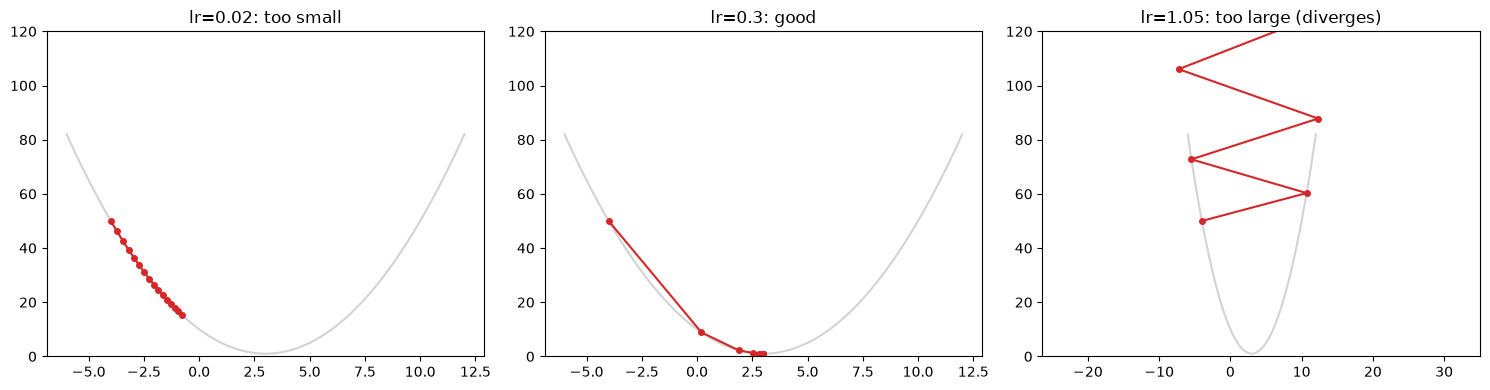

In [5]:
xs = np.linspace(-6, 12, 300)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr, title in zip(axes, [0.02, 0.3, 1.05], ["too small", "good", "too large (diverges)"]):
    h = gradient_descent_1d(df1, x_start=-4.0, lr=lr, n_steps=15)
    ax.plot(xs, f1(xs), color="lightgray")
    ax.plot(h, f1(h), "o-", color="tab:red", markersize=4)
    ax.set_title(f"lr={lr}: {title}")
    ax.set_ylim(0, 120)
fig.tight_layout(); plt.show()

## 3. Functions of several variables: partial derivatives and the gradient

A model has many parameters, so the loss is a function of many variables, e.g. $f(x, y) = x^2 + 3y^2$.

- The **partial derivative** $\partial f/\partial x$ is the slope in the x-direction with everything else held fixed.
  Here $\partial f/\partial x = 2x$ and $\partial f/\partial y = 6y$.
- The **gradient** $\nabla f$ is the vector of all partial derivatives: $\nabla f = [2x,\ 6y]$.
  It points in the direction of **steepest ascent**, so $-\nabla f$ is the steepest way downhill.

Gradient descent in many dimensions is the same formula, now with vectors:
$$ \mathbf{p}_{\text{new}} = \mathbf{p} - \eta \, \nabla f(\mathbf{p}) $$

In [6]:
def f2(p):
    x, y = p
    return x ** 2 + 3 * y ** 2

def grad_f2(p):
    x, y = p
    return np.array([2 * x, 6 * y])

def numerical_gradient(f, p, h=1e-5):
    """Nudge each coordinate separately: one partial derivative per coordinate."""
    grad = np.zeros_like(p, dtype=float)
    for i in range(len(p)):
        step = np.zeros_like(p, dtype=float)
        step[i] = h
        grad[i] = (f(p + step) - f(p - step)) / (2 * h)
    return grad

p = np.array([1.5, -2.0])
print("analytic gradient: ", grad_f2(p))
print("numerical gradient:", numerical_gradient(f2, p))   # "gradient checking"

analytic gradient:  [  3. -12.]
numerical gradient: [  3. -12.]


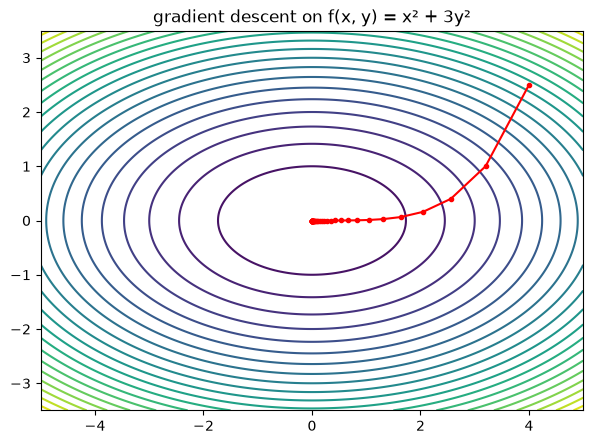

final point: [0.0005 0.    ]


In [7]:
def gradient_descent(grad_fn, p_start, lr, n_steps):
    p = np.array(p_start, dtype=float)
    path = [p.copy()]
    for _ in range(n_steps):
        p = p - lr * grad_fn(p)
        path.append(p.copy())
    return np.array(path)

path = gradient_descent(grad_f2, [4.0, 2.5], lr=0.1, n_steps=40)

# Contour plot: each line connects points with equal f (like elevation lines on a map)
gx, gy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-3.5, 3.5, 200))
Z = gx ** 2 + 3 * gy ** 2
fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(gx, gy, Z, levels=20, cmap="viridis")
ax.plot(path[:, 0], path[:, 1], "o-", color="red", markersize=3)
ax.set_title("gradient descent on f(x, y) = x² + 3y²")
ax.set_aspect("equal"); plt.show()
print("final point:", path[-1])

Notice that the path **zig-zags** in the steep y-direction. When features have very different scales, the
loss surface looks like a stretched bowl like this one, and gradient descent gets slow. That is a key reason
we **standardize features** before training (Module 10).

## 4. The chain rule

When functions are composed, $f(g(x))$, their derivatives multiply:

$$ \frac{d}{dx} f(g(x)) = f'(g(x)) \cdot g'(x) $$

Example: $L(w) = (wx - y)^2$, the squared error of a one-weight model.
The outer function is $u^2$ (derivative $2u$) and the inner is $u = wx - y$ (derivative w.r.t. $w$ is $x$). So

$$ \frac{dL}{dw} = 2(wx - y)\cdot x $$

Backpropagation in neural networks is nothing more than the chain rule applied many times.

In [8]:
x_val, y_val = 3.0, 7.0
L = lambda w: (w * x_val - y_val) ** 2
dL = lambda w: 2 * (w * x_val - y_val) * x_val      # chain rule result

w0 = 1.2
print("chain rule:", dL(w0), "  numerical:", numerical_derivative(L, w0))

chain rule: -20.400000000000002   numerical: -20.400000000098117


## 5. Putting it together: fit a line with gradient descent

Model: $\hat y = w x + b$. Loss: **mean squared error** over all n points:

$$ \text{MSE}(w, b) = \frac{1}{n}\sum_{i=1}^{n} (w x_i + b - y_i)^2 $$

Using the chain rule on each term and averaging:

$$ \frac{\partial\,\text{MSE}}{\partial w} = \frac{2}{n}\sum (w x_i + b - y_i)\,x_i \qquad
   \frac{\partial\,\text{MSE}}{\partial b} = \frac{2}{n}\sum (w x_i + b - y_i) $$

With NumPy, each sum is a single vectorized expression.

learned w=2.511, b=-1.077   (true 2.5, -1.0)


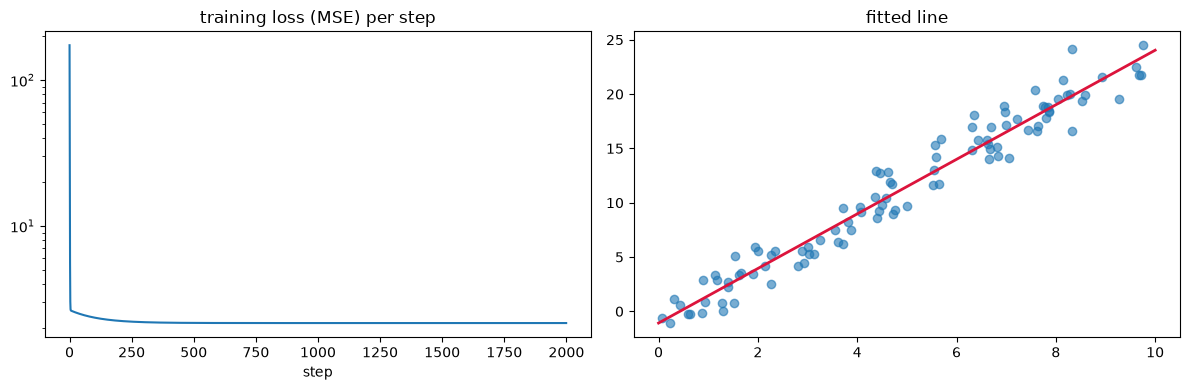

In [9]:
n = 100
x = rng.uniform(0, 10, n)
y = 2.5 * x - 1.0 + rng.normal(0, 1.5, n)       # true w=2.5, b=-1

w, b = 0.0, 0.0
lr = 0.01
losses = []
for step in range(2000):
    error = w * x + b - y                     # shape (n,): residual of every point
    losses.append(np.mean(error ** 2))
    grad_w = 2 * np.mean(error * x)
    grad_b = 2 * np.mean(error)
    w -= lr * grad_w
    b -= lr * grad_b

print(f"learned w={w:.3f}, b={b:.3f}   (true 2.5, -1.0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(losses); axes[0].set_yscale("log")
axes[0].set_title("training loss (MSE) per step"); axes[0].set_xlabel("step")
axes[1].scatter(x, y, alpha=0.6)
xs = np.linspace(0, 10, 50)
axes[1].plot(xs, w * xs + b, color="crimson", linewidth=2)
axes[1].set_title("fitted line")
fig.tight_layout(); plt.show()

🎉 You just trained a machine learning model from scratch. In Module 07 we generalize this to many features
with `X @ w`.

## Common pitfalls
- **Sign errors.** The update is `p - lr * grad` (minus). With a plus you would climb uphill.
- **Learning rate too large.** If the loss explodes to `inf`/`nan`, reduce `lr`.
- **Forgetting to average.** Using `sum` instead of `mean` makes the gradient scale with n, so the right `lr` changes with dataset size.
- **Not checking your gradients.** When you derive a gradient by hand, compare it with `numerical_gradient` first.
- **Local minima.** On non-convex functions gradient descent can get stuck. MSE for linear models is
  **convex** (bowl-shaped), so there is a single minimum.

## Recap
- A derivative is a slope; the gradient is the vector of partial derivatives and points uphill.
- Gradient descent: `params -= lr * gradient`, repeated.
- The chain rule lets us differentiate losses built from nested functions.
- Training a model = minimizing a loss with (some variant of) gradient descent.

## 📚 Further resources
🎥 video · 📖 book or guide · 📄 paper. Watching the videos alongside the lesson is the best way to use them.

- 🎥 [Essence of Calculus, chapters 1–4 (3Blue1Brown)](https://www.youtube.com/playlist?list=PLZHQObOWTQDMsr9K-rj53DwVRMYO3t5Yr)
- 🎥 [Gradient Descent, Step-by-Step (StatQuest)](https://www.youtube.com/watch?v=sDv4f4s2SB8)
- 📖 [*Mathematics for Machine Learning*, chapters 5 and 7.1](https://mml-book.github.io/)
- 📄 [Ruder (2016), *An overview of gradient descent optimization algorithms* (optional, sections 1–3)](https://arxiv.org/abs/1609.04747)